<a href="https://colab.research.google.com/github/Pomadowski/project-lab1/blob/main/SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('/content/drive/MyDrive/batteries/marketing_campaign.csv', sep='\t')

In [112]:
data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [113]:
# Check unique values in Education column
print("Unique Education levels:", data['Education'].unique())

# Map the education levels from lowest to highest
education_mapping = {
    'Basic': 1,
    '2n Cycle': 10,
    'Graduation': 100,
    'Master': 1000,
    'PhD': 10000
}

data['Education_Num'] = data['Education'].map(education_mapping)

# Display the mapping results
display(data[['Education', 'Education_Num']].head(10))

Unique Education levels: ['Graduation' 'PhD' 'Master' 'Basic' '2n Cycle']


,Education,Education_Num
0,Graduation,100
1,Graduation,100
2,Graduation,100
3,Graduation,100
4,PhD,10000
5,Master,1000
6,Graduation,100
7,PhD,10000
8,PhD,10000
9,PhD,10000


In [114]:
import pandas as pd

# Convert Kidhome and Teenhome columns to numeric, coercion handles any dirty string data safely
data['Kidhome'] = pd.to_numeric(data['Kidhome'], errors='coerce')
data['Teenhome'] = pd.to_numeric(data['Teenhome'], errors='coerce')

# Create a combined children count column
data['Children_Total'] = data['Kidhome'] + data['Teenhome']
data['Children_Total'] = pd.to_numeric(data['Children_Total'], errors='coerce')
# Display the original and the new combined columns
display(data[['Kidhome', 'Teenhome', 'Children_Total']].head(10))

,Kidhome,Teenhome,Children_Total
0,0,0,0
1,1,1,2
2,0,0,0
3,1,0,1
4,1,0,1
5,0,1,1
6,0,1,1
7,1,0,1
8,1,0,1
9,1,1,2


In [115]:
# Re-label 2 as 1 in Kidhome and Teenhome columns to simplify classification
data['Kidhome'] = data['Kidhome'].replace(2, 1)
data['Teenhome'] = data['Teenhome'].replace(2, 1)

# Re-calculate Children_Total to match the new values
data['Children_Total'] = data['Kidhome'] + data['Teenhome']

# Verify updated value distributions
print("=== Kidhome Value Counts (After Re-labeling) ===")
print(data['Kidhome'].value_counts())
print("\n=== Teenhome Value Counts (After Re-labeling) ===")
print(data['Teenhome'].value_counts())

=== Kidhome Value Counts (After Re-labeling) ===
Kidhome
0    1293
1     947
Name: count, dtype: int64

=== Teenhome Value Counts (After Re-labeling) ===
Teenhome
0    1158
1    1082
Name: count, dtype: int64


In [116]:
import pandas as pd

# Convert Year_Birth to numeric, coercing any errors
year_birth_numeric = pd.to_numeric(data['Year_Birth'], errors='coerce')

# Calculate Age by subtracting from 2026
data['Age'] = 2026 - year_birth_numeric


q_low = data['Age'].quantile(0.005) # get 1st percentile
q_hi  = data['Age'].quantile(0.995) # get 99th percentile
data = data[(data['Age'] < q_hi) & (data['Age'] > q_low)]



# Display the results
display(data[['Year_Birth', 'Age']].head())

,Year_Birth,Age
0,1957,69
1,1954,72
2,1965,61
3,1984,42
4,1981,45


<Axes: >

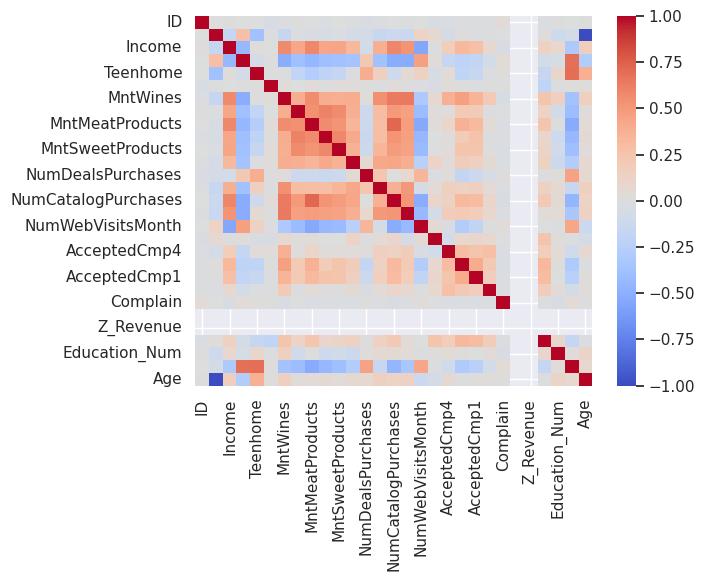

In [117]:
corr = data.corr(numeric_only=True)
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, center=0)

In [118]:
# Columns to drop (matching the casing of the actual dataset columns)
columns_to_drop = ['ID','Education_Num', 'Year_Birth','Z_CostContact','Recency', 'Z_Revenue', 'Complain', 'AcceptedCmp1','AcceptedCmp2','AcceptedCmp3', 'AcceptedCmp4','AcceptedCmp5','Response']

# Drop columns if they exist in the dataframe
data = data.drop(columns=[col for col in columns_to_drop if col in data.columns])

# Display the remaining columns to verify
display(data.head())

,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Children_Total,Age
0,Graduation,Single,58138.0,0,0,04-09-2012,635,88,546,172,88,88,3,8,10,4,7,0,69
1,Graduation,Single,46344.0,1,1,08-03-2014,11,1,6,2,1,6,2,1,1,2,5,2,72
2,Graduation,Together,71613.0,0,0,21-08-2013,426,49,127,111,21,42,1,8,2,10,4,0,61
3,Graduation,Together,26646.0,1,0,10-02-2014,11,4,20,10,3,5,2,2,0,4,6,1,42
4,PhD,Married,58293.0,1,0,19-01-2014,173,43,118,46,27,15,5,5,3,6,5,1,45


<Axes: >

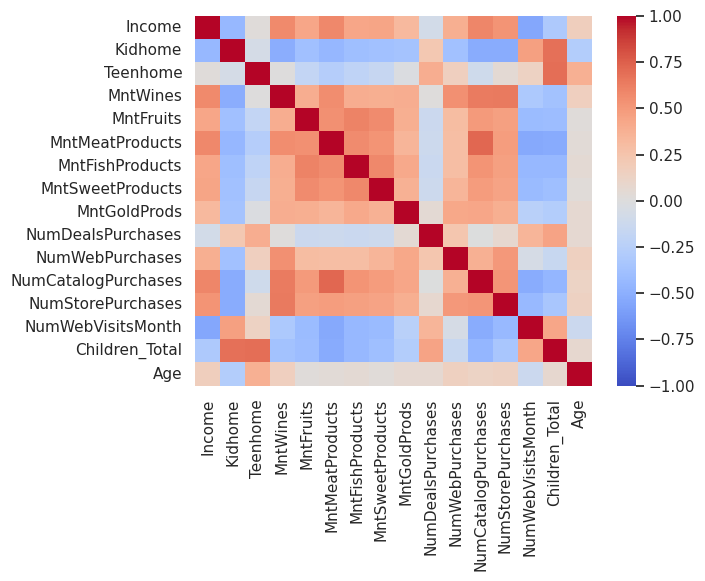

In [119]:
corr = data.corr(numeric_only=True)
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, center=0)

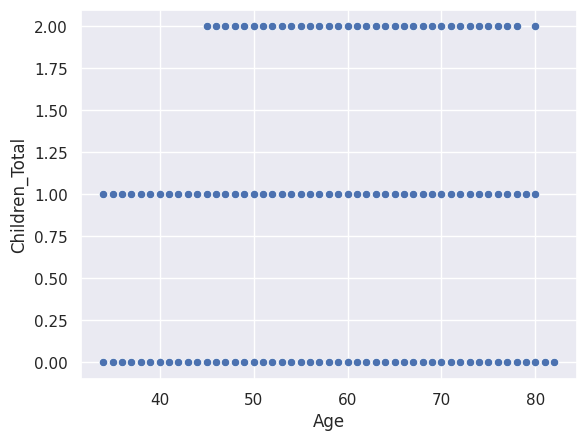

In [120]:
sns.set_theme()
sns.scatterplot(x=data['Age'], y=data['Children_Total'],)
#plt.xscale('log')
#plt.yscale('log')
plt.show()

In [121]:
# Identify columns starting with 'Mnt'
mnt_cols = [col for col in data.columns if col.startswith('Mnt')]

# Normalize using Min-Max scaling to bring values between 0 and 1
data_normalized = (data[mnt_cols] - data[mnt_cols].min()) / (data[mnt_cols].max() - data[mnt_cols].min())

# Average the normalized columns into a new column
data['Concentrated_Purchase_Volume'] = data_normalized.mean(axis=1)

# Display the results
display(data[mnt_cols + ['Concentrated_Purchase_Volume']].head())

,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,Concentrated_Purchase_Volume
0,635,88,546,172,88,88,0.404306
1,11,1,6,2,1,6,0.007328
2,426,49,127,111,21,42,0.204938
3,11,4,20,10,3,5,0.017149
4,173,43,118,46,27,15,0.120344


In [122]:
# Columns to drop (matching the casing of the actual dataset columns)
columns_to_drop = [col for col in data.columns if col.startswith('Mnt')]

# Drop columns if they exist in the dataframe
data = data.drop(columns=[col for col in columns_to_drop if col in data.columns])

# Display the remaining columns to verify


# Drop non-numeric columns from the dataframe
data = data.select_dtypes(include=[np.number])

# Display the remaining columns to verify they are all numeric
display(data.head())


,Income,Kidhome,Teenhome,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Children_Total,Age,Concentrated_Purchase_Volume
0,58138.0,0,0,3,8,10,4,7,0,69,0.404306
1,46344.0,1,1,2,1,1,2,5,2,72,0.007328
2,71613.0,0,0,1,8,2,10,4,0,61,0.204938
3,26646.0,1,0,2,2,0,4,6,1,42,0.017149
4,58293.0,1,0,5,5,3,6,5,1,45,0.120344


<Axes: >

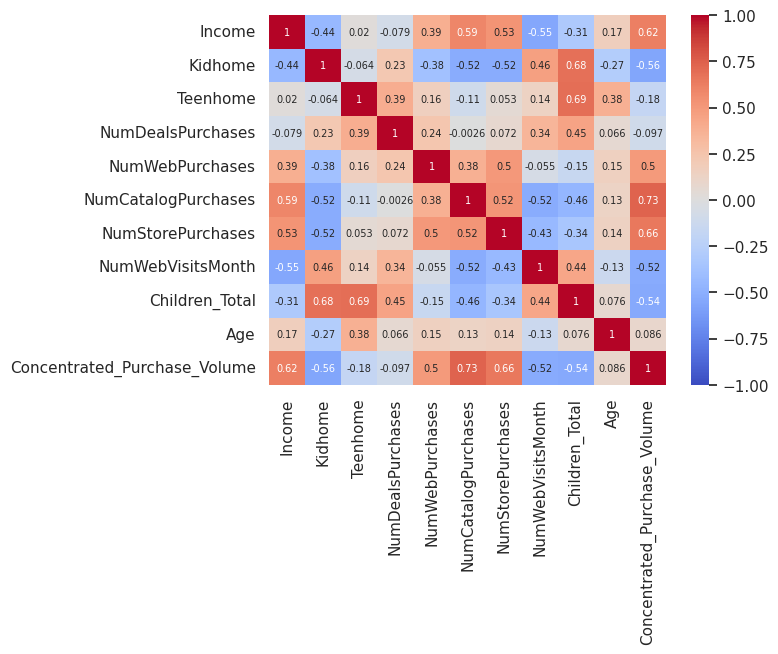

In [123]:
corr = data.corr(numeric_only=True)
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, center=0,annot=True,annot_kws={'size': 7})

<Axes: xlabel='NumWebPurchases', ylabel='NumCatalogPurchases'>

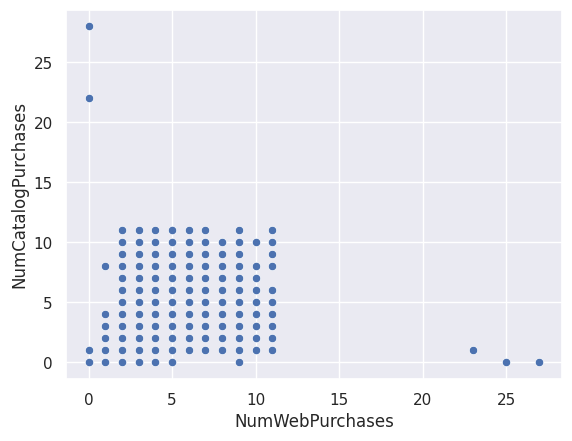

In [124]:

import seaborn as sns
sns.set_theme()
sns.scatterplot(x=data['NumWebPurchases'], y=data['NumCatalogPurchases'])

In [125]:

q_low = data['NumWebPurchases'].quantile(0.005) # get 1st percentile
q_hi  = data['NumWebPurchases'].quantile(0.995) # get 99th percentile
data = data[(data['NumWebPurchases'] < q_hi)]

q_low = data['NumCatalogPurchases'].quantile(0.005) # get 1st percentile
q_hi  = data['NumCatalogPurchases'].quantile(0.995) # get 99th percentile
data = data[(data['NumCatalogPurchases'] < q_hi)]

q_low = data['NumWebVisitsMonth'].quantile(0.005) # get 1st percentile
q_hi  = data['NumWebVisitsMonth'].quantile(0.995) # get 99th percentile
data = data[(data['NumWebVisitsMonth'] < q_hi)]

data.describe()

,Income,Kidhome,Teenhome,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Children_Total,Age,Concentrated_Purchase_Volume
count,2109.000000,2131.000000,2131.000000,2131.000000,2131.000000,2131.000000,2131.000000,2131.000000,2131.000000,2131.000000,2131.000000
mean,51721.161214,0.436415,0.487565,2.302675,3.917879,2.497419,5.766776,5.297044,0.923979,57.097137,0.129151
std,24767.605724,0.496057,0.499963,1.814363,2.455867,2.605226,3.217403,2.274060,0.681646,11.420534,0.131808
min,7500.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,34.000000,0.000878
25%,34961.000000,0.000000,0.000000,1.000000,2.000000,0.000000,3.000000,3.000000,0.000000,49.000000,0.019738
50%,50611.000000,0.000000,0.000000,2.000000,3.000000,2.000000,5.000000,6.000000,1.000000,56.000000,0.070998
75%,67506.000000,1.000000,1.000000,3.000000,6.000000,4.000000,8.000000,7.000000,1.000000,66.000000,0.217355
max,666666.000000,1.000000,1.000000,15.000000,10.000000,10.000000,13.000000,9.000000,2.000000,82.000000,0.596320


<Axes: >

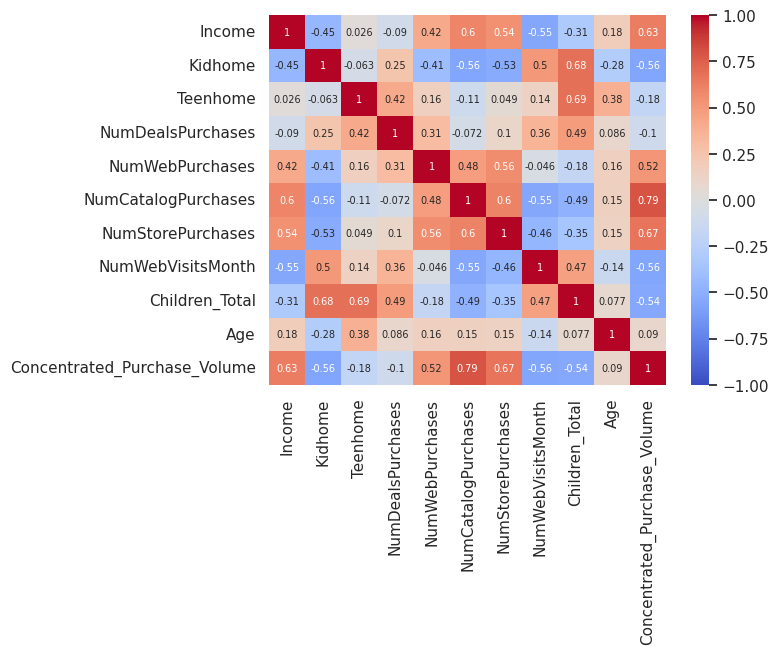

In [126]:
corr = data.corr(numeric_only=True)
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, center=0,annot=True,annot_kws={'size': 7})


In [127]:
from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

# Prepare features: Drop the targets 'Kidhome' and 'Teenhome', and 'Children_Total'
df_clean = data.dropna().copy()

X = df_clean.drop(columns=['Kidhome', 'Teenhome', 'Children_Total'])
y_kid = df_clean['Kidhome']
y_teen = df_clean['Teenhome']

# Split data: 80% train+validation, 20% test
X_train_val_kid, X_test_kid, y_train_val_kid, y_test_kid = train_test_split(X, y_kid, test_size=0.2, random_state=1)
X_train_val_teen, X_test_teen, y_train_val_teen, y_test_teen = train_test_split(X, y_teen, test_size=0.2, random_state=1)

# Further split train+validation into 87.5% train and 12.5% validation
# (This makes the overall split 70% Train, 10% Validation, 20% Test)
X_train_kid, X_val_kid, y_train_kid, y_val_kid = train_test_split(X_train_val_kid, y_train_val_kid, test_size=0.125, random_state=1)
X_train_teen, X_val_teen, y_train_teen, y_val_teen = train_test_split(X_train_val_teen, y_train_val_teen, test_size=0.125, random_state=1)

# Standardize features using training set parameters
scaler_kid = StandardScaler()
X_train_kid_scaled = scaler_kid.fit_transform(X_train_kid)
X_val_kid_scaled = scaler_kid.transform(X_val_kid)
X_test_kid_scaled = scaler_kid.transform(X_test_kid)

scaler_teen = StandardScaler()
X_train_teen_scaled = scaler_teen.fit_transform(X_train_teen)
X_val_teen_scaled = scaler_teen.transform(X_val_teen)
X_test_teen_scaled = scaler_teen.transform(X_test_teen)

# Train SVM Classifier for Kidhome with class_weight='balanced'
svm_kid = svm.SVC(kernel='rbf', class_weight='balanced', random_state=42)
svm_kid.fit(X_train_kid_scaled, y_train_kid)

# Evaluate Kidhome
y_val_pred_kid = svm_kid.predict(X_val_kid_scaled)
y_test_pred_kid = svm_kid.predict(X_test_kid_scaled)

# Train SVM Classifier for Teenhome with class_weight='balanced'
svm_teen = svm.SVC(kernel='rbf', class_weight='balanced', random_state=42)
svm_teen.fit(X_train_teen_scaled, y_train_teen)

# Evaluate Teenhome
y_val_pred_teen = svm_teen.predict(X_val_teen_scaled)
y_test_pred_teen = svm_teen.predict(X_test_teen_scaled)

# Print Reports
print("=== Kidhome SVM Classifier: Validation Set Report ===")
print(classification_report(y_val_kid, y_val_pred_kid, zero_division=0))
print("=== Kidhome SVM Classifier: Test Set Report ===")
print(classification_report(y_test_kid, y_test_pred_kid, zero_division=0))

print("\n=== Teenhome SVM Classifier: Validation Set Report ===")
print(classification_report(y_val_teen, y_val_pred_teen, zero_division=0))
print("=== Teenhome SVM Classifier: Test Set Report ===")
print(classification_report(y_test_teen, y_test_pred_teen, zero_division=0))

=== Kidhome SVM Classifier: Validation Set Report ===
              precision    recall  f1-score   support

           0       0.92      0.82      0.87       127
           1       0.77      0.89      0.82        84

    accuracy                           0.85       211
   macro avg       0.84      0.86      0.85       211
weighted avg       0.86      0.85      0.85       211

=== Kidhome SVM Classifier: Test Set Report ===
              precision    recall  f1-score   support

           0       0.93      0.86      0.89       238
           1       0.84      0.91      0.87       184

    accuracy                           0.88       422
   macro avg       0.88      0.89      0.88       422
weighted avg       0.89      0.88      0.88       422


=== Teenhome SVM Classifier: Validation Set Report ===
              precision    recall  f1-score   support

           0       0.89      0.84      0.87       121
           1       0.80      0.87      0.83        90

    accuracy            

In [128]:
# Print the count of samples for values 0, 1, and 2 in Kidhome and Teenhome columns
print("=== Kidhome Value Counts (0, 1) ===")
print(df_clean['Kidhome'].value_counts().loc[[0, 1]])

print("\n=== Teenhome Value Counts (0, 1) ===")
print(df_clean['Teenhome'].value_counts().loc[[0, 1]])

=== Kidhome Value Counts (0, 1) ===
Kidhome
0    1192
1     917
Name: count, dtype: int64

=== Teenhome Value Counts (0, 1) ===
Teenhome
0    1083
1    1026
Name: count, dtype: int64


In [129]:
from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

# Prepare features
df_clean = data.dropna().copy()

X = df_clean.drop(columns=['Kidhome', 'Teenhome', 'Children_Total'])
y_kid = df_clean['Kidhome']
y_teen = df_clean['Teenhome']

# 60% train, 20% validation, 20% test
# First split: 80% train_val, 20% test
previous_acc_val_teen = 0
previous_acc_val_kid = 0


X_train_val_kid, X_test_kid, y_train_val_kid, y_test_kid = train_test_split(X, y_kid, test_size=0.2, random_state=1)
X_train_val_teen, X_test_teen, y_train_val_teen, y_test_teen = train_test_split(X, y_teen, test_size=0.2,random_state=1)

  # Second split: Out of 80% train_val, we take 25% for validation so that 0.8 * 0.25 = 20% overall validation set
  # This leaves 60% overall for training.
X_train_kid, X_val_kid, y_train_kid, y_val_kid = train_test_split(X_train_val_kid, y_train_val_kid, test_size=0.25,random_state=1)
X_train_teen, X_val_teen, y_train_teen, y_val_teen = train_test_split(X_train_val_teen, y_train_val_teen, test_size=0.25,random_state=1)

  # Standardize features using training set parameters
scaler_kid = StandardScaler()
X_train_kid_scaled = scaler_kid.fit_transform(X_train_kid)
X_val_kid_scaled = scaler_kid.transform(X_val_kid)
X_test_kid_scaled = scaler_kid.transform(X_test_kid)

scaler_teen = StandardScaler()
X_train_teen_scaled = scaler_teen.fit_transform(X_train_teen)
X_val_teen_scaled = scaler_teen.transform(X_val_teen)
X_test_teen_scaled = scaler_teen.transform(X_test_teen)

  # Train SVM Classifier for Kidhome with class_weight='balanced'
for N in range(1,100):
  svm_kid = svm.SVC(kernel='rbf', class_weight='balanced',random_state=N)
  svm_kid.fit(X_train_kid_scaled, y_train_kid)

  # Evaluate Kidhome
  y_val_pred_kid = svm_kid.predict(X_val_kid_scaled)
  y_test_pred_kid = svm_kid.predict(X_test_kid_scaled)

  # Train SVM Classifier for Teenhome with class_weight='balanced'
  svm_teen = svm.SVC(kernel='rbf', class_weight='balanced',random_state=N)
  svm_teen.fit(X_train_teen_scaled, y_train_teen)

  # Evaluate Teenhome
  y_val_pred_teen = svm_teen.predict(X_val_teen_scaled)
  y_test_pred_teen = svm_teen.predict(X_test_teen_scaled)

  # Calculate correct accuracy score using the validation set
  acc_val_teen = accuracy_score(y_val_teen, y_val_pred_teen)
  acc_val_kid = accuracy_score(y_val_kid, y_val_pred_kid)

  print(f"Teenhome Validation Accuracy: {acc_val_teen:.4f}")
  print(f"Kidhome Validation Accuracy: {acc_val_kid:.4f}")
  if acc_val_teen > previous_acc_val_teen:
    current_best_model_teen = svm_teen
    previous_acc_val_teen = acc_val_teen
  if acc_val_kid > previous_acc_val_kid:
    current_best_model_kid = svm_kid
    previous_acc_val_kid = acc_val_kid

acc_val_best_teen= accuracy_score(y_val_teen, current_best_model_teen.predict(X_val_teen_scaled))
acc_val_best_kid= accuracy_score(y_val_kid, current_best_model_kid.predict(X_val_kid_scaled))
print(f"Best Teenhome Validation Accuracy: {acc_val_best_teen:.4f}")
print(f"Best Kidhome Validation Accuracy: {acc_val_best_kid:.4f}")
acc_test_best_teen = accuracy_score(y_test_teen, current_best_model_teen.predict(X_test_teen_scaled))
acc_test_best_kid = accuracy_score(y_test_kid, current_best_model_kid.predict(X_test_kid_scaled))
print(f"Best Teenhome Test Accuracy: {acc_test_best_teen:.4f}")
print(f"Best Kidhome Test Accuracy: {acc_test_best_kid:.4f}")

Teenhome Validation Accuracy: 0.8744
Kidhome Validation Accuracy: 0.8602
Teenhome Validation Accuracy: 0.8744
Kidhome Validation Accuracy: 0.8602
Teenhome Validation Accuracy: 0.8744
Kidhome Validation Accuracy: 0.8602
Teenhome Validation Accuracy: 0.8744
Kidhome Validation Accuracy: 0.8602
Teenhome Validation Accuracy: 0.8744
Kidhome Validation Accuracy: 0.8602
Teenhome Validation Accuracy: 0.8744
Kidhome Validation Accuracy: 0.8602
Teenhome Validation Accuracy: 0.8744
Kidhome Validation Accuracy: 0.8602
Teenhome Validation Accuracy: 0.8744
Kidhome Validation Accuracy: 0.8602
Teenhome Validation Accuracy: 0.8744
Kidhome Validation Accuracy: 0.8602
Teenhome Validation Accuracy: 0.8744
Kidhome Validation Accuracy: 0.8602
Teenhome Validation Accuracy: 0.8744
Kidhome Validation Accuracy: 0.8602
Teenhome Validation Accuracy: 0.8744
Kidhome Validation Accuracy: 0.8602
Teenhome Validation Accuracy: 0.8744
Kidhome Validation Accuracy: 0.8602
Teenhome Validation Accuracy: 0.8744
Kidhome Valida

In [130]:
from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
import numpy as np

# Prepare features
df_clean = data.dropna().copy()

X = df_clean.drop(columns=['Kidhome', 'Teenhome', 'Children_Total'])
y_kid = df_clean['Kidhome']
y_teen = df_clean['Teenhome']

# 60% train, 20% validation, 20% test
# First split: 80% train_val, 20% test
previous_acc_val_teen = 0
previous_acc_val_kid = 0


X_train_val_kid, X_test_kid, y_train_val_kid, y_test_kid = train_test_split(X, y_kid, test_size=0.2, random_state=1)
X_train_val_teen, X_test_teen, y_train_val_teen, y_test_teen = train_test_split(X, y_teen, test_size=0.2,random_state=1)

  # Second split: Out of 80% train_val, we take 25% for validation so that 0.8 * 0.25 = 20% overall validation set
  # This leaves 60% overall for training.
X_train_kid, X_val_kid, y_train_kid, y_val_kid = train_test_split(X_train_val_kid, y_train_val_kid, test_size=0.25,random_state=1)
X_train_teen, X_val_teen, y_train_teen, y_val_teen = train_test_split(X_train_val_teen, y_train_val_teen, test_size=0.25,random_state=1)

  # Standardize features using training set parameters
scaler_kid = StandardScaler()
X_train_kid_scaled = scaler_kid.fit_transform(X_train_kid)
X_val_kid_scaled = scaler_kid.transform(X_val_kid)
X_test_kid_scaled = scaler_kid.transform(X_test_kid)

scaler_teen = StandardScaler()
X_train_teen_scaled = scaler_teen.fit_transform(X_train_teen)
X_val_teen_scaled = scaler_teen.transform(X_val_teen)
X_test_teen_scaled = scaler_teen.transform(X_test_teen)

  # Train SVM Classifier for Kidhome with class_weight='balanced'

coeff_range = np.arange(0.1, 6.0, 0.1)

for N in range(1,6):
  for M in coeff_range:
    # Train SVM Classifier for Kidhome with class_weight='balanced'
    svm_kid = svm.SVC(kernel='poly', degree=N, coef0=M,class_weight='balanced')
    svm_kid.fit(X_train_kid_scaled, y_train_kid)

    # Evaluate Kidhome
    y_val_pred_kid = svm_kid.predict(X_val_kid_scaled)
    y_test_pred_kid = svm_kid.predict(X_test_kid_scaled)

    # Train SVM Classifier for Teenhome with class_weight='balanced'
    svm_teen = svm.SVC(kernel='poly', degree=N, coef0=M,class_weight='balanced')
    svm_teen.fit(X_train_teen_scaled, y_train_teen)

    # Evaluate Teenhome
    y_val_pred_teen = svm_teen.predict(X_val_teen_scaled)
    y_test_pred_teen = svm_teen.predict(X_test_teen_scaled)

    # Calculate correct accuracy score using the validation set
    acc_val_teen = accuracy_score(y_val_teen, y_val_pred_teen)
    acc_val_kid = accuracy_score(y_val_kid, y_val_pred_kid)

    print(f"Teenhome Validation Accuracy: {acc_val_teen:.4f}")
    print(f"Kidhome Validation Accuracy: {acc_val_kid:.4f}")
    if acc_val_teen > previous_acc_val_teen:
      current_best_model_teen = svm_teen
      previous_acc_val_teen = acc_val_teen
    if acc_val_kid > previous_acc_val_kid:
      current_best_model_kid = svm_kid
      previous_acc_val_kid = acc_val_kid

acc_val_best_teen= accuracy_score(y_val_teen, current_best_model_teen.predict(X_val_teen_scaled))
acc_val_best_kid= accuracy_score(y_val_kid, current_best_model_kid.predict(X_val_kid_scaled))
print(f"Best Teenhome Validation Accuracy: {acc_val_best_teen:.4f}")
print(f"Best Kidhome Validation Accuracy: {acc_val_best_kid:.4f}")
acc_test_best_teen = accuracy_score(y_test_teen, current_best_model_teen.predict(X_test_teen_scaled))
acc_test_best_kid = accuracy_score(y_test_kid, current_best_model_kid.predict(X_test_kid_scaled))
print(f"Best Teenhome Test Accuracy: {acc_test_best_teen:.4f}")
print(f"Best Kidhome Test Accuracy: {acc_test_best_kid:.4f}")

Teenhome Validation Accuracy: 0.7820
Kidhome Validation Accuracy: 0.8483
Teenhome Validation Accuracy: 0.7820
Kidhome Validation Accuracy: 0.8483
Teenhome Validation Accuracy: 0.7820
Kidhome Validation Accuracy: 0.8483
Teenhome Validation Accuracy: 0.7820
Kidhome Validation Accuracy: 0.8483
Teenhome Validation Accuracy: 0.7820
Kidhome Validation Accuracy: 0.8483
Teenhome Validation Accuracy: 0.7820
Kidhome Validation Accuracy: 0.8483
Teenhome Validation Accuracy: 0.7820
Kidhome Validation Accuracy: 0.8483
Teenhome Validation Accuracy: 0.7820
Kidhome Validation Accuracy: 0.8483
Teenhome Validation Accuracy: 0.7820
Kidhome Validation Accuracy: 0.8483
Teenhome Validation Accuracy: 0.7820
Kidhome Validation Accuracy: 0.8483
Teenhome Validation Accuracy: 0.7820
Kidhome Validation Accuracy: 0.8483
Teenhome Validation Accuracy: 0.7820
Kidhome Validation Accuracy: 0.8483
Teenhome Validation Accuracy: 0.7820
Kidhome Validation Accuracy: 0.8483
Teenhome Validation Accuracy: 0.7820
Kidhome Valida

In [131]:
print(classification_report(y_test_teen, current_best_model_teen.predict(X_test_teen_scaled)))

              precision    recall  f1-score   support

           0       0.88      0.89      0.89       215
           1       0.88      0.88      0.88       207

    accuracy                           0.88       422
   macro avg       0.88      0.88      0.88       422
weighted avg       0.88      0.88      0.88       422



In [132]:
print(classification_report(y_test_kid, current_best_model_kid.predict(X_test_kid_scaled)))

              precision    recall  f1-score   support

           0       0.90      0.86      0.88       238
           1       0.83      0.88      0.85       184

    accuracy                           0.87       422
   macro avg       0.87      0.87      0.87       422
weighted avg       0.87      0.87      0.87       422



In [136]:
from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
import numpy as np
from sklearn.decomposition import PCA




# Prepare features
df_clean = data.dropna().copy()

X = df_clean.drop(columns=['Kidhome', 'Teenhome', 'Children_Total'])
y_kid = df_clean['Kidhome']
y_teen = df_clean['Teenhome']

# 60% train, 20% validation, 20% test
# First split: 80% train_val, 20% test
previous_acc_val_teen = 0
previous_acc_val_kid = 0

pca = PCA().set_output(transform="pandas").fit(X)
data_pca = pca.transform(X)



X_train_val_kid, X_test_kid, y_train_val_kid, y_test_kid = train_test_split(data_pca, y_kid, test_size=0.2, random_state=1)
X_train_val_teen, X_test_teen, y_train_val_teen, y_test_teen = train_test_split(data_pca, y_teen, test_size=0.2,random_state=1)

  # Second split: Out of 80% train_val, we take 25% for validation so that 0.8 * 0.25 = 20% overall validation set
  # This leaves 60% overall for training.
X_train_kid, X_val_kid, y_train_kid, y_val_kid = train_test_split(X_train_val_kid, y_train_val_kid, test_size=0.25,random_state=1)
X_train_teen, X_val_teen, y_train_teen, y_val_teen = train_test_split(X_train_val_teen, y_train_val_teen, test_size=0.25,random_state=1)

  # Standardize features using training set parameters
scaler_kid = StandardScaler()
X_train_kid_scaled = scaler_kid.fit_transform(X_train_kid)
X_val_kid_scaled = scaler_kid.transform(X_val_kid)
X_test_kid_scaled = scaler_kid.transform(X_test_kid)

scaler_teen = StandardScaler()
X_train_teen_scaled = scaler_teen.fit_transform(X_train_teen)
X_val_teen_scaled = scaler_teen.transform(X_val_teen)
X_test_teen_scaled = scaler_teen.transform(X_test_teen)

  # Train SVM Classifier for Kidhome with class_weight='balanced'

coeff_range = np.arange(0.1, 7.0, 0.1)

for N in range(7,8):
  for M in coeff_range:
    # Train SVM Classifier for Kidhome with class_weight='balanced'
    svm_kid = svm.SVC(kernel='poly', degree=N, coef0=M,class_weight='balanced')
    svm_kid.fit(X_train_kid_scaled, y_train_kid)

    # Evaluate Kidhome
    y_val_pred_kid = svm_kid.predict(X_val_kid_scaled)
    y_test_pred_kid = svm_kid.predict(X_test_kid_scaled)

    # Train SVM Classifier for Teenhome with class_weight='balanced'
    svm_teen = svm.SVC(kernel='poly', degree=N, coef0=M,class_weight='balanced')
    svm_teen.fit(X_train_teen_scaled, y_train_teen)

    # Evaluate Teenhome
    y_val_pred_teen = svm_teen.predict(X_val_teen_scaled)
    y_test_pred_teen = svm_teen.predict(X_test_teen_scaled)

    # Calculate correct accuracy score using the validation set
    acc_val_teen = accuracy_score(y_val_teen, y_val_pred_teen)
    acc_val_kid = accuracy_score(y_val_kid, y_val_pred_kid)

    print(f"Teenhome Validation Accuracy: {acc_val_teen:.4f}")
    print(f"Kidhome Validation Accuracy: {acc_val_kid:.4f}")
    if acc_val_teen > previous_acc_val_teen:
      current_best_model_teen = svm_teen
      previous_acc_val_teen = acc_val_teen
    if acc_val_kid > previous_acc_val_kid:
      current_best_model_kid = svm_kid
      previous_acc_val_kid = acc_val_kid

acc_val_best_teen= accuracy_score(y_val_teen, current_best_model_teen.predict(X_val_teen_scaled))
acc_val_best_kid= accuracy_score(y_val_kid, current_best_model_kid.predict(X_val_kid_scaled))
print(f"Best Teenhome Validation Accuracy: {acc_val_best_teen:.4f}")
print(f"Best Kidhome Validation Accuracy: {acc_val_best_kid:.4f}")
acc_test_best_teen = accuracy_score(y_test_teen, current_best_model_teen.predict(X_test_teen_scaled))
acc_test_best_kid = accuracy_score(y_test_kid, current_best_model_kid.predict(X_test_kid_scaled))
print(f"Best Teenhome Test Accuracy: {acc_test_best_teen:.4f}")
print(f"Best Kidhome Test Accuracy: {acc_test_best_kid:.4f}")

Teenhome Validation Accuracy: 0.7607
Kidhome Validation Accuracy: 0.7583
Teenhome Validation Accuracy: 0.7891
Kidhome Validation Accuracy: 0.7962
Teenhome Validation Accuracy: 0.8318
Kidhome Validation Accuracy: 0.8341
Teenhome Validation Accuracy: 0.8720
Kidhome Validation Accuracy: 0.8483
Teenhome Validation Accuracy: 0.8626
Kidhome Validation Accuracy: 0.8578
Teenhome Validation Accuracy: 0.8626
Kidhome Validation Accuracy: 0.8649
Teenhome Validation Accuracy: 0.8578
Kidhome Validation Accuracy: 0.8626
Teenhome Validation Accuracy: 0.8531
Kidhome Validation Accuracy: 0.8626
Teenhome Validation Accuracy: 0.8531
Kidhome Validation Accuracy: 0.8720
Teenhome Validation Accuracy: 0.8483
Kidhome Validation Accuracy: 0.8673
Teenhome Validation Accuracy: 0.8460
Kidhome Validation Accuracy: 0.8744
Teenhome Validation Accuracy: 0.8412
Kidhome Validation Accuracy: 0.8839
Teenhome Validation Accuracy: 0.8412
Kidhome Validation Accuracy: 0.8791
Teenhome Validation Accuracy: 0.8507
Kidhome Valida

In [134]:
print(classification_report(y_test_teen, current_best_model_teen.predict(X_test_teen_scaled)))

              precision    recall  f1-score   support

           0       0.87      0.90      0.89       215
           1       0.89      0.86      0.88       207

    accuracy                           0.88       422
   macro avg       0.88      0.88      0.88       422
weighted avg       0.88      0.88      0.88       422



In [135]:
print(classification_report(y_test_kid, current_best_model_kid.predict(X_test_kid_scaled)))

              precision    recall  f1-score   support

           0       0.92      0.86      0.89       238
           1       0.83      0.90      0.86       184

    accuracy                           0.88       422
   macro avg       0.87      0.88      0.88       422
weighted avg       0.88      0.88      0.88       422

